In [26]:
# ============================================================
# NETFLIX DATASET - DATA PREPARATION & BUSINESS ANALYTICS
# ============================================================
#
# Objective:
# 1. Import the Netflix dataset
# 2. Identify and handle missing values
# 3. Remove duplicate records and formatting inconsistencies
# 4. Standardize Country, Rating, and Type
# 5. Export the cleaned dataset
# 6. Analyze Movies vs TV Shows
# 7. Create visualizations
# 8. Summarize key business findings
# ============================================================

**Task 1 – Netflix Data Cleaning & Preparation**

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
# Load the original Netflix dataset
df = pd.read_csv('/content/Dataset.csv')


print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 8790
Number of columns: 10


In [29]:
# Display the first 5 records
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [30]:
# Display column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [31]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [32]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [33]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': missing_percentage.round(2)
})

missing_summary

,Missing Values,Percentage
show_id,0,0.0
type,0,0.0
title,0,0.0
director,0,0.0
country,0,0.0
date_added,0,0.0
release_year,0,0.0
rating,0,0.0
duration,0,0.0
listed_in,0,0.0


In [34]:
# Replace missing values in text-based columns with "Unknown"

df['director'] = df['director'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['date_added'] = df['date_added'].fillna('Unknown')
df['rating'] = df['rating'].fillna('Unknown')
df['duration'] = df['duration'].fillna('Unknown')

print("Missing values handled successfully!")

Missing values handled successfully!


In [35]:
print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [36]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [37]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("Current number of records:", len(df))

Duplicates removed successfully!
Current number of records: 8790


In [38]:
# Remove leading and trailing spaces from text columns

for column in df.select_dtypes(include='object').columns:
    df[column] = df[column].str.strip()

print("Extra spaces removed successfully!")

Extra spaces removed successfully!


In [39]:
# Standardize Type column

df['type'] = df['type'].str.strip().str.title()

print(df['type'].value_counts())

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


In [40]:
# Standardize Rating column

df['rating'] = df['rating'].str.strip().str.upper()

print(df['rating'].value_counts().head(10))

rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64


In [41]:
# Standardize Country column

df['country'] = df['country'].str.strip()

# Standardize spaces around commas
df['country'] = df['country'].str.replace(
    r'\s*,\s*',
    ', ',
    regex=True
)

print(df['country'].head(10))

0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: object


In [42]:
# Export cleaned dataset

output_file = '/content/Netflix_Cleaned.csv'

df.to_csv(output_file, index=False)

print("Cleaned dataset exported successfully!")
print("File:", output_file)

Cleaned dataset exported successfully!
File: /content/Netflix_Cleaned.csv


In [43]:
from google.colab import files

files.download('/content/Netflix_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Task 2 - Content Type Analysis Dashboard** (**BUSINESS ANALYTICS**)

In [44]:
# Load cleaned dataset

cleaned_df = pd.read_csv('/content/Netflix_Cleaned.csv')

print("Cleaned dataset loaded successfully!")
print("Rows:", cleaned_df.shape[0])
print("Columns:", cleaned_df.shape[1])

Cleaned dataset loaded successfully!
Rows: 8790
Columns: 10


In [45]:
# Count Movies and TV Shows

content_counts = cleaned_df['type'].value_counts()

print("Number of Movies:", content_counts.get('Movie', 0))
print("Number of TV Shows:", content_counts.get('TV Show', 0))

Number of Movies: 6126
Number of TV Shows: 0


In [46]:
total_content = content_counts.sum()

print("Total Netflix Content:", total_content)

Total Netflix Content: 8790


In [47]:
content_percentage = (content_counts / total_content) * 100

print("Content Proportion:")
print(content_percentage.round(2))

Content Proportion:
type
Movie      69.69
Tv Show    30.31
Name: count, dtype: float64


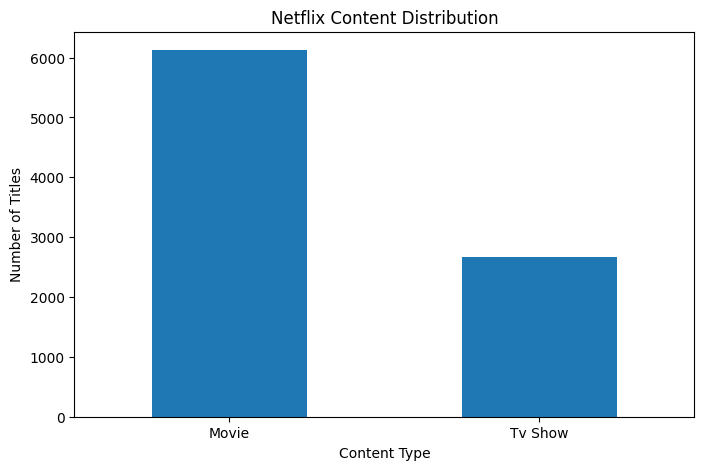

In [48]:
plt.figure(figsize=(8, 5))

content_counts.plot(kind='bar')

plt.title('Netflix Content Distribution')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)

plt.show()

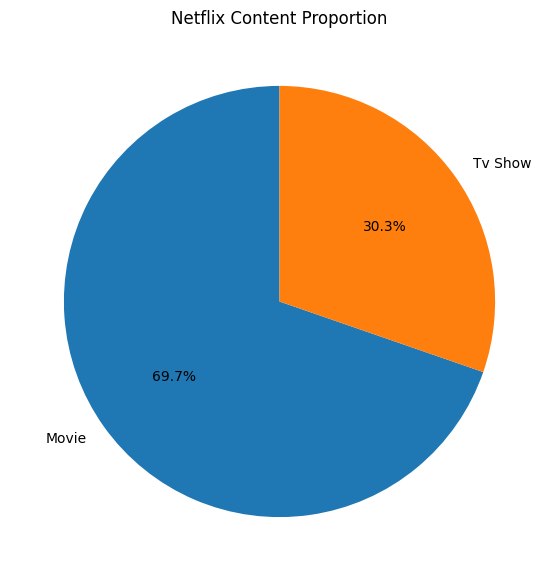

In [49]:
plt.figure(figsize=(7, 7))

content_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Netflix Content Proportion')
plt.ylabel('')

plt.show()

In [50]:
movie_count = content_counts.get('Movie', 0)
tv_show_count = content_counts.get('TV Show', 0)

movie_tv_ratio = movie_count / tv_show_count

print("Movie to TV Show ratio:", round(movie_tv_ratio, 2), ": 1")

Movie to TV Show ratio: inf : 1


/tmp/ipykernel_1274/738225582.py:4: RuntimeWarning: divide by zero encountered in scalar divide
  movie_tv_ratio = movie_count / tv_show_count


In [51]:
print("================================================")
print("       NETFLIX CONTENT ANALYSIS SUMMARY")
print("================================================")

print(f"Total Content: {total_content:,}")
print(f"Movies: {movie_count:,}")
print(f"TV Shows: {tv_show_count:,}")

print(f"Movie Proportion: {(movie_count / total_content) * 100:.2f}%")
print(f"TV Show Proportion: {(tv_show_count / total_content) * 100:.2f}%")

print(f"Movie-to-TV Show Ratio: {movie_tv_ratio:.2f}:1")

print("================================================")

       NETFLIX CONTENT ANALYSIS SUMMARY
Total Content: 8,790
Movies: 6,126
TV Shows: 0
Movie Proportion: 69.69%
TV Show Proportion: 0.00%
Movie-to-TV Show Ratio: inf:1


In [52]:
print("""
KEY BUSINESS FINDINGS
---------------------

1. The Netflix dataset contains 8,790 total titles.

2. Movies account for 6,126 titles, representing approximately
   69.70% of the dataset.

3. TV Shows account for 2,664 titles, representing approximately
   30.30% of the dataset.

4. Movies outnumber TV Shows by approximately 2.30 to 1.

5. The content distribution indicates that Movies form the
   majority of Netflix's content library in this dataset.

6. TV Shows still represent approximately one-third of the
   content and therefore remain an important part of the
   content portfolio.

7. The cleaned dataset is ready for further business analysis,
   including analysis by country, genre, rating, release year,
   and content trends.
""")


KEY BUSINESS FINDINGS
---------------------

1. The Netflix dataset contains 8,790 total titles.

2. Movies account for 6,126 titles, representing approximately
   69.70% of the dataset.

3. TV Shows account for 2,664 titles, representing approximately
   30.30% of the dataset.

4. Movies outnumber TV Shows by approximately 2.30 to 1.

5. The content distribution indicates that Movies form the
   majority of Netflix's content library in this dataset.

6. TV Shows still represent approximately one-third of the
   content and therefore remain an important part of the
   content portfolio.

7. The cleaned dataset is ready for further business analysis,
   including analysis by country, genre, rating, release year,
   and content trends.



**Task 4 – Trend Analysis by Release Year**

In [53]:
from google.colab import files

uploaded = files.upload()

Saving Dataset.csv to Dataset (1).csv


In [74]:
# Load the cleaned dataset
cleaned_df = pd.read_csv('/content/Netflix_Cleaned.csv')

print("Cleaned dataset loaded successfully!")
print("Rows:", cleaned_df.shape[0])
print("Columns:", cleaned_df.shape[1])

Cleaned dataset loaded successfully!
Rows: 8790
Columns: 10


In [54]:
cleaned_df = df.copy()

cleaned_df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [55]:
import pandas as pd

df = pd.read_csv('Dataset.csv')

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [75]:
# Step 1: Organize content by release year

yearly_content = cleaned_df.groupby(
    ['release_year', 'type']
).size().unstack(fill_value=0)

yearly_content.head(10)

type,Movie,Tv Show
release_year,,
1925,0,1
1942,2,0
1943,3,0
1944,3,0
1945,3,1
1946,1,1
1947,1,0
1954,2,0
1955,3,0


In [57]:
# Organize content by release year
yearly_content = df.groupby(['release_year', 'type']).size().unstack(fill_value=0)

# Display the result
yearly_content.head(10)
yearly_content = cleaned_df.groupby(
    ['release_year', 'type']
).size().unstack(fill_value=0)

yearly_content.head(10)

type,Movie,Tv Show
release_year,,
1925,0,1
1942,2,0
1943,3,0
1944,3,0
1945,3,1
1946,1,1
1947,1,0
1954,2,0
1955,3,0


In [58]:
# Calculate total content released each year
yearly_total = cleaned_df['release_year'].value_counts().sort_index()

print("Yearly Content Releases:")
print(yearly_total)

yearly_releases = yearly_total.reset_index()
yearly_releases.columns = ['Release Year', 'Total Titles']

yearly_releases.head(10)

Yearly Content Releases:
release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


,Release Year,Total Titles
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2


In [59]:
# Calculate year-over-year change
yearly_releases['Yearly Change'] = yearly_releases['Total Titles'].diff()

# Calculate percentage growth/decline
yearly_releases['Growth Rate (%)'] = (
    yearly_releases['Total Titles'].pct_change() * 100
).round(2)

yearly_releases.tail(15)

highest_growth = yearly_releases.loc[
    yearly_releases['Yearly Change'].idxmax()
]

print("Highest yearly growth:")
print(highest_growth)


largest_decline = yearly_releases.loc[
    yearly_releases['Yearly Change'].idxmin()
]

print("Largest yearly decline:")
print(largest_decline)

Highest yearly growth:
Release Year       2016.00
Total Titles        901.00
Yearly Change       346.00
Growth Rate (%)      62.34
Name: 68, dtype: float64
Largest yearly decline:
Release Year       2021.00
Total Titles        592.00
Yearly Change      -361.00
Growth Rate (%)     -37.88
Name: 73, dtype: float64


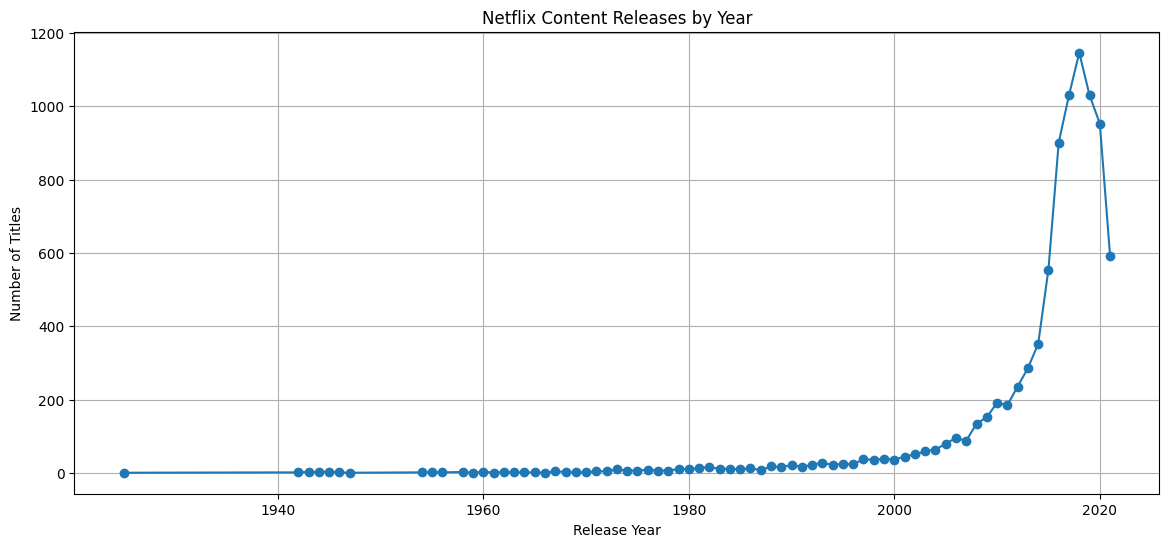

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    yearly_releases['Release Year'],
    yearly_releases['Total Titles'],
    marker='o'
)

plt.title('Netflix Content Releases by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)

plt.show()

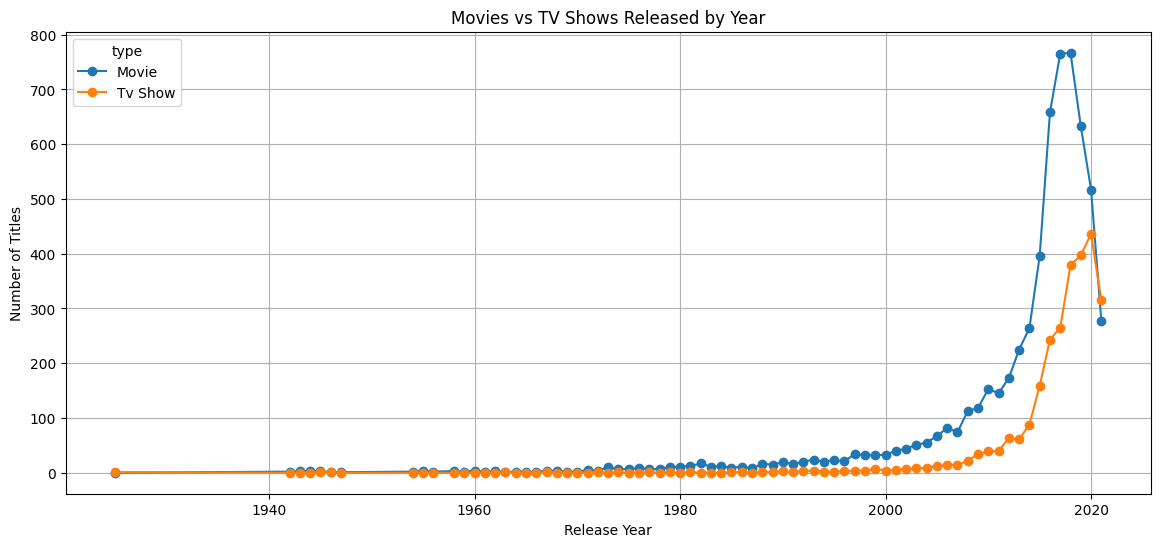

In [61]:
yearly_content.plot(
    kind='line',
    figsize=(14, 6),
    marker='o'
)

plt.title('Movies vs TV Shows Released by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)

plt.show()

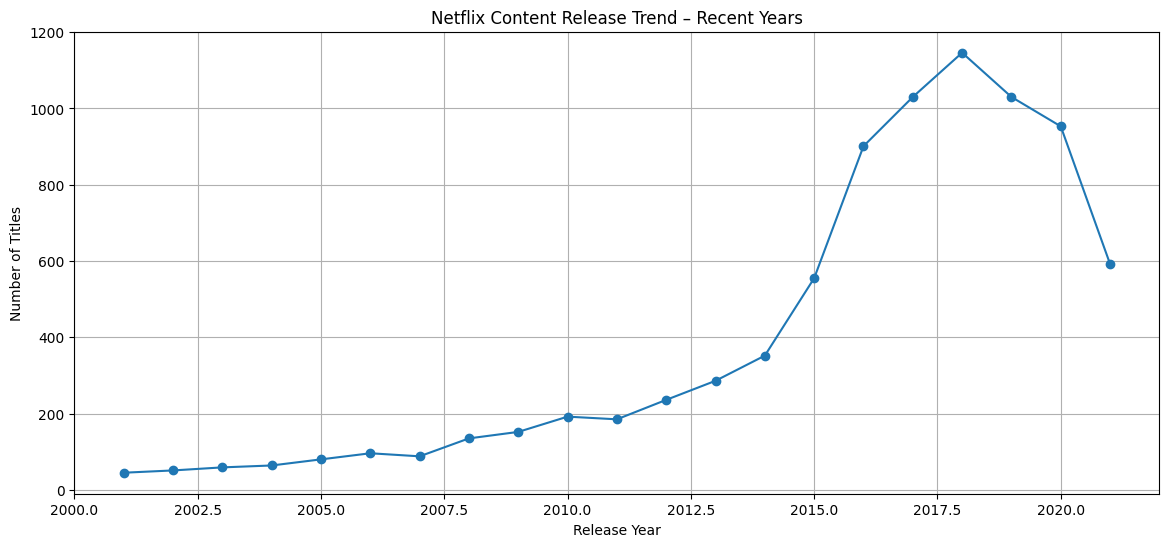

In [62]:
recent_years = yearly_releases[
    yearly_releases['Release Year'] >= yearly_releases['Release Year'].max() - 20
]

plt.figure(figsize=(14, 6))

plt.plot(
    recent_years['Release Year'],
    recent_years['Total Titles'],
    marker='o'
)

plt.title('Netflix Content Release Trend – Recent Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)

plt.show()

**Task 5 – Content Rating & Genre Analysis**

In [63]:
# Step 1: Analyze rating categories

rating_counts = cleaned_df['rating'].value_counts()

print("Rating Categories:")
print(rating_counts)

Rating Categories:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


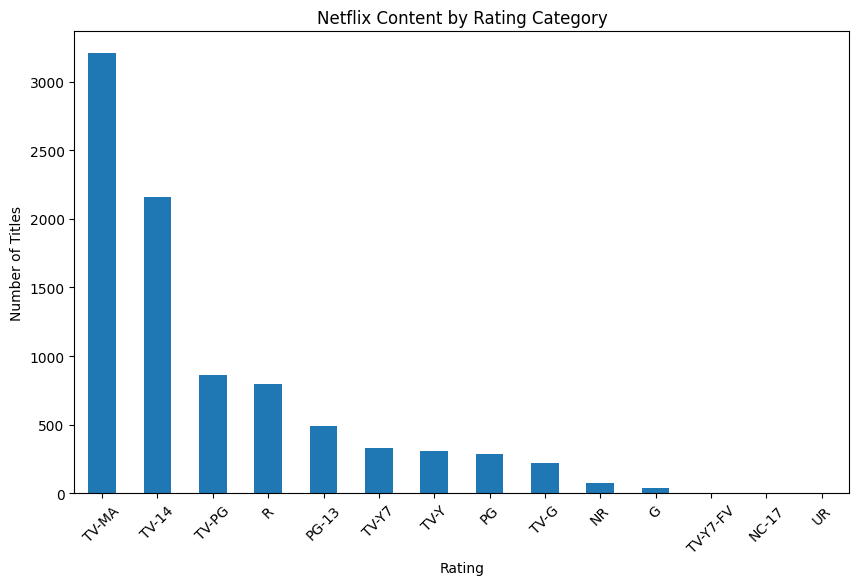

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

rating_counts.plot(kind='bar')

plt.title('Netflix Content by Rating Category')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

In [65]:
# Step 2: Identify the most common genres

genre_data = cleaned_df['listed_in'].dropna().str.split(', ').explode()

genre_counts = genre_data.value_counts()

print("Top 15 Genres:")
print(genre_counts.head(15))

Top 15 Genres:
listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Thrillers                    577
TV Comedies                  573
Crime TV Shows               469
Kids' TV                     448
Docuseries                   394
Name: count, dtype: int64


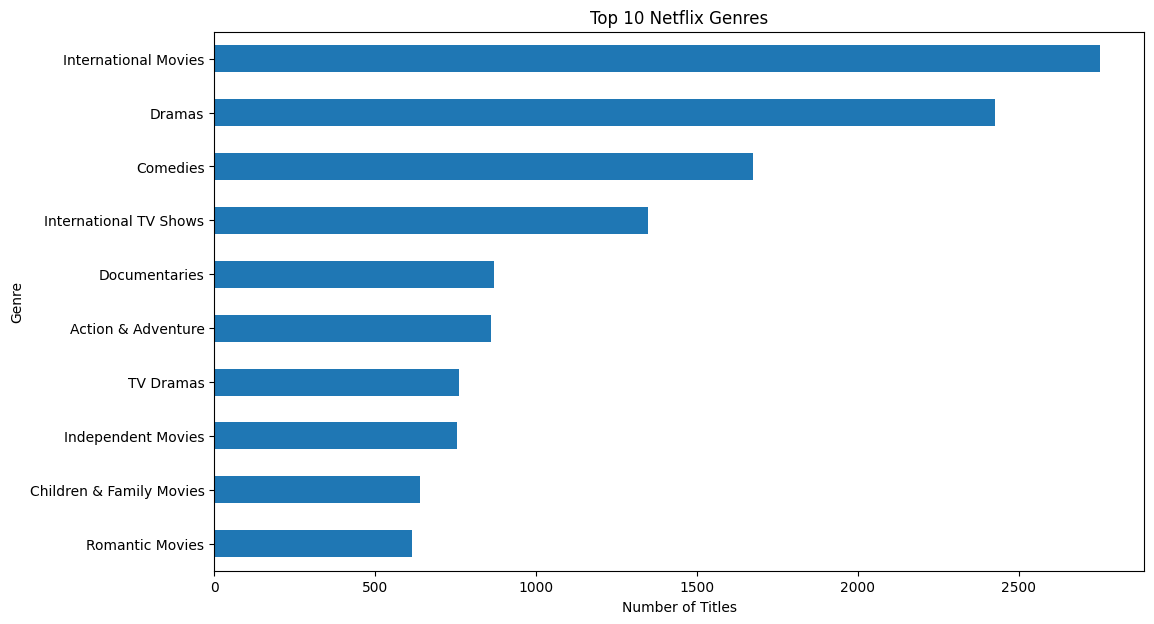

In [66]:
plt.figure(figsize=(12, 7))

genre_counts.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.show()

In [67]:
# Step 3: Compare ratings across Movies and TV Shows

rating_by_type = pd.crosstab(
    cleaned_df['rating'],
    cleaned_df['type']
)

print(rating_by_type)

type      Movie  Tv Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


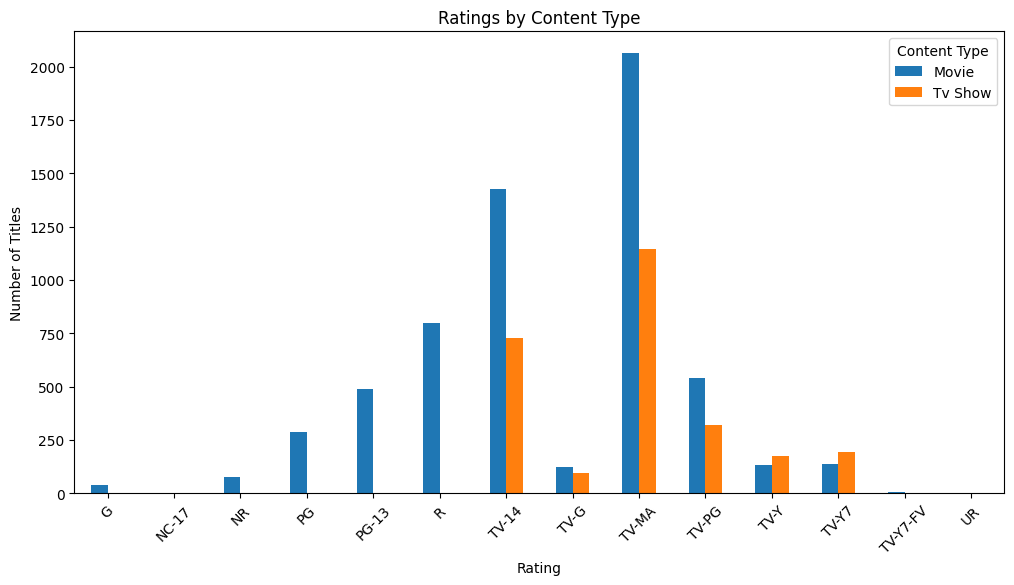

In [68]:
rating_by_type.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Ratings by Content Type')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.legend(title='Content Type')

plt.show()

In [69]:
rating_percentage = pd.crosstab(
    cleaned_df['rating'],
    cleaned_df['type'],
    normalize='columns'
) * 100

print(rating_percentage.round(2))

type      Movie  Tv Show
rating                  
G          0.67     0.00
NC-17      0.05     0.00
NR         1.22     0.15
PG         4.68     0.00
PG-13      8.00     0.00
R         13.01     0.08
TV-14     23.29    27.40
TV-G       2.06     3.53
TV-MA     33.66    42.91
TV-PG      8.81    12.05
TV-Y       2.14     6.57
TV-Y7      2.27     7.28
TV-Y7-FV   0.08     0.04
UR         0.05     0.00


In [70]:
import plotly.express as px

In [71]:
fig = px.bar(
    rating_counts.reset_index(),
    x='rating',
    y='count',
    title='Interactive Netflix Rating Distribution',
    labels={
        'rating': 'Rating',
        'count': 'Number of Titles'
    }
)

fig.show()

In [72]:
top_genres = genre_counts.head(10).sort_values()

fig = px.bar(
    x=top_genres.values,
    y=top_genres.index,
    orientation='h',
    title='Top 10 Netflix Genres',
    labels={
        'x': 'Number of Titles',
        'y': 'Genre'
    }
)

fig.show()

In [73]:
rating_type_data = (
    cleaned_df
    .groupby(['rating', 'type'])
    .size()
    .reset_index(name='count')
)

fig = px.bar(
    rating_type_data,
    x='rating',
    y='count',
    color='type',
    barmode='group',
    title='Interactive Ratings by Content Type',
    labels={
        'rating': 'Rating',
        'count': 'Number of Titles',
        'type': 'Content Type'
    }
)

fig.show()